In [2]:
# Load the datasets
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")

# Load customer features and scaled data
customer_features = pd.read_csv(
    "Customer_Feature_Engineered.csv"
)

X_scaled = pd.read_csv(
    "Customer_Features_Scaled.csv"
)

print("Customer features:", customer_features.shape)
print("Scaled features:", X_scaled.shape)

assert len(customer_features) == len(X_scaled)
assert X_scaled.isnull().sum().sum() == 0

display(customer_features.head())

Customer features: (5044, 13)
Scaled features: (5044, 7)


,Customer ID,Total_Sales,Total_Profit,Total_Units,Order_Count,Transaction_Count,Product_Count,Average_Sales_Per_Order,Average_Units_Per_Order,Gross_Profit_Margin,Preferred_Division,Main_Region,Preferred_Ship_Mode
0,100006,11.25,7.35,3,1,1,1,11.250000,3.0,65.333333,Chocolate,Atlantic,Standard Class
1,100013,18.00,12.50,5,1,3,1,18.000000,5.0,69.444444,Chocolate,Pacific,Standard Class
2,100041,21.25,14.31,6,3,3,3,7.083333,2.0,67.341176,Chocolate,Interior,Standard Class
3,100048,36.80,24.08,11,2,3,2,18.400000,5.5,65.434783,Chocolate,Atlantic,Standard Class
4,100055,18.30,12.40,5,2,2,2,9.150000,2.5,67.759563,Chocolate,Atlantic,Standard Class


In [3]:
# Train the K-Means model
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

cluster_labels = kmeans.fit_predict(X_scaled)

# Add the cluster assignment to each customer
customer_features["Cluster"] = cluster_labels

print("K-Means model trained successfully!")
print("Number of clusters:", kmeans.n_clusters)
print("Inertia:", round(kmeans.inertia_, 4))
print(
    "Silhouette Score:",
    round(silhouette_score(X_scaled, cluster_labels), 4)
)

display(customer_features.head(10))

K-Means model trained successfully!
Number of clusters: 4
Inertia: 11846.4973
Silhouette Score: 0.4589


,Customer ID,Total_Sales,Total_Profit,Total_Units,Order_Count,Transaction_Count,Product_Count,Average_Sales_Per_Order,Average_Units_Per_Order,Gross_Profit_Margin,Preferred_Division,Main_Region,Preferred_Ship_Mode,Cluster
0,100006,11.25,7.35,3,1,1,1,11.250000,3.0,65.333333,Chocolate,Atlantic,Standard Class,0
1,100013,18.00,12.50,5,1,3,1,18.000000,5.0,69.444444,Chocolate,Pacific,Standard Class,0
2,100041,21.25,14.31,6,3,3,3,7.083333,2.0,67.341176,Chocolate,Interior,Standard Class,3
3,100048,36.80,24.08,11,2,3,2,18.400000,5.5,65.434783,Chocolate,Atlantic,Standard Class,3
4,100055,18.30,12.40,5,2,2,2,9.150000,2.5,67.759563,Chocolate,Atlantic,Standard Class,0
5,100069,7.20,5.00,2,1,1,1,7.200000,2.0,69.444444,Chocolate,Interior,Standard Class,0
6,100083,3.60,2.40,1,1,1,1,3.600000,1.0,66.666667,Chocolate,Pacific,Standard Class,0
7,100090,29.25,18.99,9,1,2,1,29.250000,9.0,64.923077,Chocolate,Pacific,Standard Class,2
8,100097,33.70,23.00,10,2,2,2,16.850000,5.0,68.249258,Chocolate,Atlantic,Second Class,3
9,100111,182.41,125.93,52,5,14,5,36.482000,10.4,69.036785,Chocolate,Atlantic,Standard Class,1


,Cluster,Customer_Count,Percentage
0,0,2413,47.84
1,1,339,6.72
2,2,896,17.76
3,3,1396,27.68


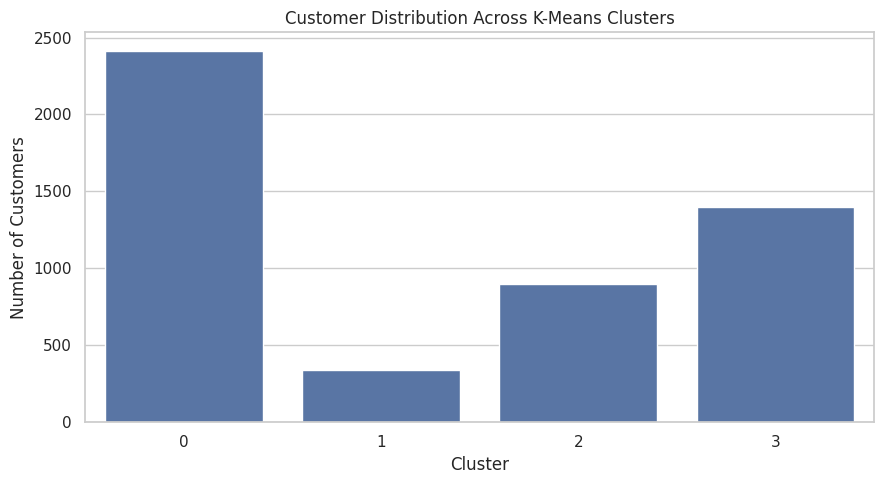

In [4]:
# Check the number of customers in each cluster
cluster_counts = (
    customer_features["Cluster"]
    .value_counts()
    .sort_index()
)

cluster_distribution = pd.DataFrame({
    "Cluster": cluster_counts.index,
    "Customer_Count": cluster_counts.values,
    "Percentage": (
        cluster_counts.values
        / len(customer_features) * 100
    ).round(2)
})

display(cluster_distribution)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=cluster_distribution,
    x="Cluster",
    y="Customer_Count"
)

plt.title("Customer Distribution Across K-Means Clusters")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

In [5]:
# Analyze cluster characteristics
profile_columns = [
    "Total_Sales",
    "Total_Profit",
    "Total_Units",
    "Order_Count",
    "Product_Count",
    "Average_Sales_Per_Order",
    "Average_Units_Per_Order"
]

cluster_profile = (
    customer_features
    .groupby("Cluster")[profile_columns]
    .mean()
    .round(2)
)

print("Average customer profile by cluster:")
display(cluster_profile)

print("Median customer profile by cluster:")
display(
    customer_features
    .groupby("Cluster")[profile_columns]
    .median()
    .round(2)
)

Average customer profile by cluster:


,Total_Sales,Total_Profit,Total_Units,Order_Count,Product_Count,Average_Sales_Per_Order,Average_Units_Per_Order
Cluster,,,,,,,
0,10.97,7.32,3.15,1.12,1.12,10.03,2.88
1,101.42,65.19,24.88,3.77,3.53,29.66,7.01
2,35.08,23.18,9.56,1.23,1.22,28.77,7.81
3,35.47,23.57,10.07,2.48,2.46,14.57,4.13


Median customer profile by cluster:


,Total_Sales,Total_Profit,Total_Units,Order_Count,Product_Count,Average_Sales_Per_Order,Average_Units_Per_Order
Cluster,,,,,,,
0,10.80,7.35,3.0,1.0,1.0,9.75,3.0
1,87.90,58.05,23.0,4.0,4.0,25.23,6.5
2,28.80,19.60,8.0,1.0,1.0,26.00,7.0
3,33.38,22.38,10.0,2.0,2.0,14.35,4.0


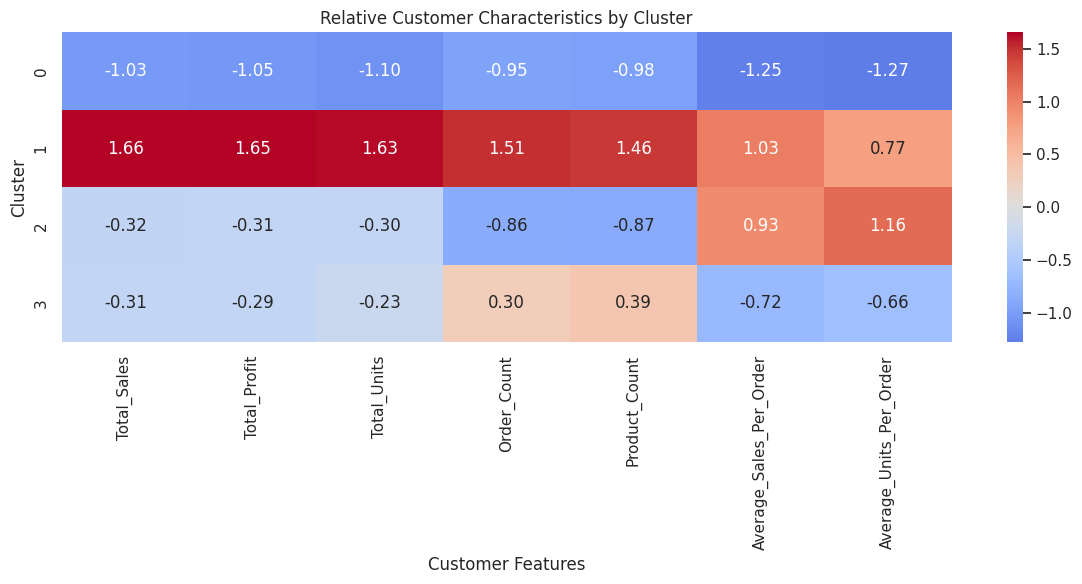

In [6]:
# Visualize cluster profiles
profile_for_heatmap = (
    customer_features
    .groupby("Cluster")[profile_columns]
    .mean()
)

# Standardize columns for visualization only
profile_heatmap = (
    profile_for_heatmap - profile_for_heatmap.mean()
) / profile_for_heatmap.std(ddof=0)

plt.figure(figsize=(12, 6))

sns.heatmap(
    profile_heatmap,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Relative Customer Characteristics by Cluster")
plt.xlabel("Customer Features")
plt.ylabel("Cluster")
plt.tight_layout()
plt.show()

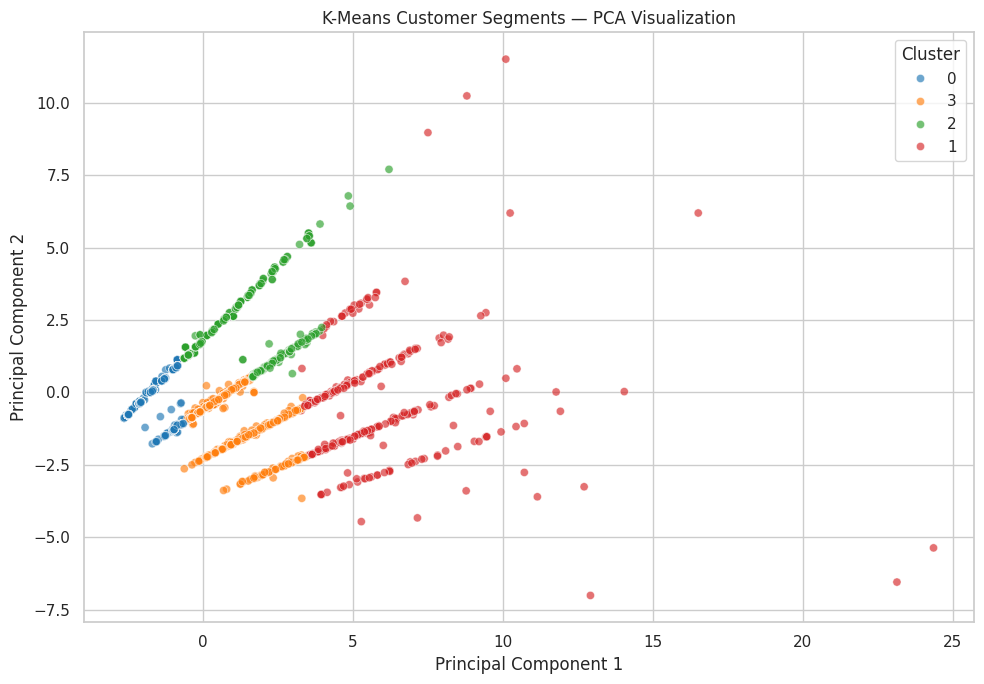

Variance explained by two PCA components: 92.42 %


In [7]:
# Visualize the clusters using PCA
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Cluster": cluster_labels.astype(str)
})

plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_df,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="tab10",
    alpha=0.65,
    s=35
)

plt.title("K-Means Customer Segments — PCA Visualization")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

print(
    "Variance explained by two PCA components:",
    round(pca.explained_variance_ratio_.sum() * 100, 2),
    "%"
)

Preferred_Division,Chocolate,Other,Sugar
Cluster,,,
0,97.22,2.24,0.54
1,99.12,0.88,0.00
2,97.10,2.90,0.00
3,99.93,0.07,0.00


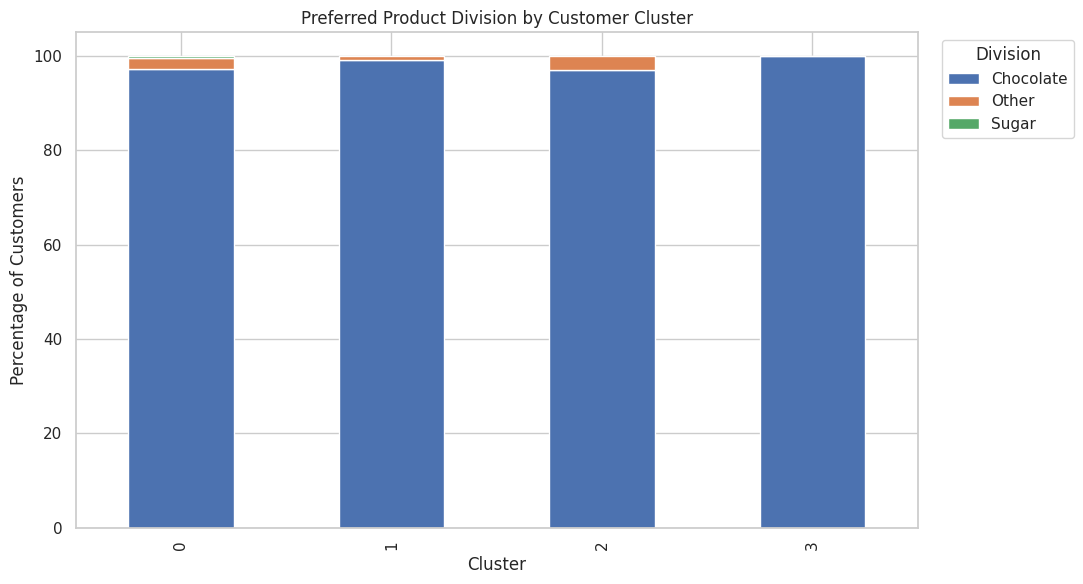

In [8]:
# Identify the preferred product division for each cluster
division_counts = pd.crosstab(
    customer_features["Cluster"],
    customer_features["Preferred_Division"],
    normalize="index"
) * 100

display(division_counts.round(2))

division_counts.plot(
    kind="bar",
    stacked=True,
    figsize=(11, 6)
)

plt.title("Preferred Product Division by Customer Cluster")
plt.xlabel("Cluster")
plt.ylabel("Percentage of Customers")
plt.legend(title="Division", bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

In [12]:
# Export the trained model and results
import joblib
import os
from sklearn.preprocessing import StandardScaler

customer_features.to_csv(
    "KMeans_Customer_Segments.csv",
    index=False
)

cluster_profile.to_csv(
    "KMeans_Cluster_Profiles.csv"
)

joblib.dump(
    kmeans,
    "kmeans_customer_segmentation.pkl"
)

joblib.dump(
    pca,
    "customer_segmentation_pca.pkl"
)

# Load the scaler if it exists, otherwise reconstruct it
if os.path.exists("scaler.pkl"):
    scaler = joblib.load("scaler.pkl")
else:
    print("scaler.pkl not found. Reconstructing and fitting a new StandardScaler...")
    scaler = StandardScaler()
    # Reconstruct the unscaled features from customer_features using profile_columns
    unscaled_data = customer_features[profile_columns]
    scaler.fit(unscaled_data)
    joblib.dump(scaler, "scaler.pkl")

joblib.dump(
    {
        "feature_columns": X_scaled.columns.tolist(),
        "scaler": scaler
    },
    "customer_segmentation_preprocessing.pkl"
)

print("Step 5 output files saved.")

Step 5 output files saved.
